In [1]:
import pandas as pd

df = pd.read_csv('/content/customer_churn_model_v2.csv')

print(df.head())

    CustomerID  Age Region  TenureMonths SubscriptionType  MonthlyChargesINR  \
0  CUST-100001   57  South            33         Standard             767.25   
1  CUST-100002   44  South            45            Basic             476.72   
2  CUST-100003   64  South            57            Basic             414.81   
3  CUST-100004   57   East            44              Pro            1171.76   
4  CUST-100005   58  North            49              Pro            1130.19   

   TotalChargesINR    ContractType  SupportTickets  LatePayments  \
0         23893.97  Month-to-Month               4             1   
1         21627.46        Two Year               0             1   
2         22500.07        One Year               1             1   
3         50309.16  Month-to-Month               4             0   
4         55980.21  Month-to-Month               3             0   

  PaymentMethod AutoPay Churn  
0           UPI     Yes   Yes  
1           UPI     Yes   Yes  
2           UP

In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()


Dataset Shape: (800, 13)

Column Names:
Index(['CustomerID', 'Age', 'Region', 'TenureMonths', 'SubscriptionType',
       'MonthlyChargesINR', 'TotalChargesINR', 'ContractType',
       'SupportTickets', 'LatePayments', 'PaymentMethod', 'AutoPay', 'Churn'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         800 non-null    object 
 1   Age                800 non-null    int64  
 2   Region             800 non-null    object 
 3   TenureMonths       800 non-null    int64  
 4   SubscriptionType   800 non-null    object 
 5   MonthlyChargesINR  800 non-null    float64
 6   TotalChargesINR    800 non-null    float64
 7   ContractType       800 non-null    object 
 8   SupportTickets     800 non-null    int64  
 9   LatePayments       800 non-null    int64  
 10  PaymentMethod 

In [3]:
print(df['Churn'].value_counts())

Churn
No     466
Yes    334
Name: count, dtype: int64


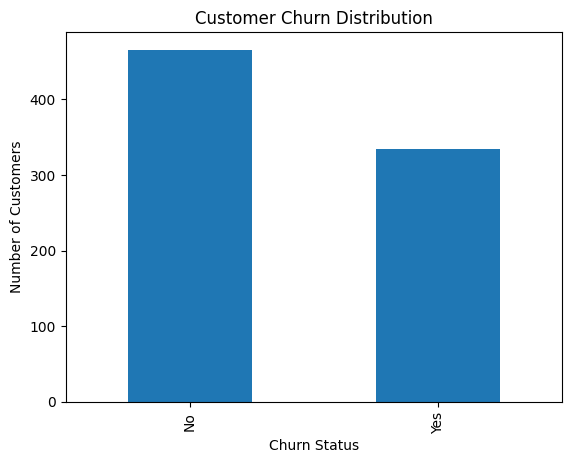

In [4]:
import matplotlib.pyplot as plt

df['Churn'].value_counts().plot(kind='bar')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()

In [5]:
X = df.drop(['CustomerID', 'Churn'], axis=1)

y = df['Churn']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   Age Region  TenureMonths SubscriptionType  MonthlyChargesINR  \
0   57  South            33         Standard             767.25   
1   44  South            45            Basic             476.72   
2   64  South            57            Basic             414.81   
3   57   East            44              Pro            1171.76   
4   58  North            49              Pro            1130.19   

   TotalChargesINR    ContractType  SupportTickets  LatePayments  \
0         23893.97  Month-to-Month               4             1   
1         21627.46        Two Year               0             1   
2         22500.07        One Year               1             1   
3         50309.16  Month-to-Month               4             0   
4         55980.21  Month-to-Month               3             0   

  PaymentMethod AutoPay  
0           UPI     Yes  
1           UPI     Yes  
2           UPI      No  
3          Card     Yes  
4        Wallet      No  

Target Variable

In [6]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (800, 11)
y Shape: (800,)


In [7]:
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [8]:
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns

categorical_features = X.select_dtypes(include=['object']).columns

print("Numerical Features:")
print(list(numerical_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['Age', 'TenureMonths', 'MonthlyChargesINR', 'TotalChargesINR', 'SupportTickets', 'LatePayments']

Categorical Features:
['Region', 'SubscriptionType', 'ContractType', 'PaymentMethod', 'AutoPay']


In [10]:
numerical_transformer = Pipeline(steps=[
    ('scaler', MinMaxScaler())
])

categorical_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (640, 11)
Testing Data: (160, 11)
Training Target: (640,)
Testing Target: (160,)


In [13]:
from sklearn.linear_model import LogisticRegression

In [14]:
from sklearn.pipeline import Pipeline

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [15]:
model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [16]:
y_pred = model.predict(X_test)

print("Actual Churn Values:")
print(y_test.head(10).values)

print("\nPredicted Churn Values:")
print(y_pred[:10])

Actual Churn Values:
['Yes' 'No' 'No' 'Yes' 'Yes' 'No' 'Yes' 'No' 'No' 'Yes']

Predicted Churn Values:
['No' 'No' 'No' 'Yes' 'Yes' 'No' 'No' 'Yes' 'No' 'No']


In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label='Yes')
recall = recall_score(y_test, y_pred, pos_label='Yes')
f1 = f1_score(y_test, y_pred, pos_label='Yes')

print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

Model Evaluation Results
------------------------
Accuracy: 0.6375
Precision: 0.5763
Recall: 0.5075
F1-Score: 0.5397


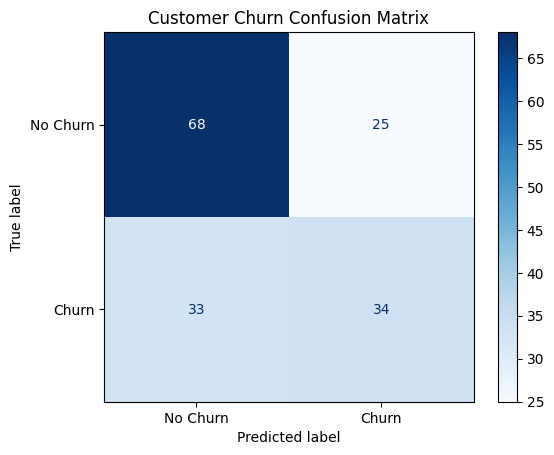

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=['No', 'Yes'])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

display.plot(cmap='Blues')

plt.title('Customer Churn Confusion Matrix')
plt.show()

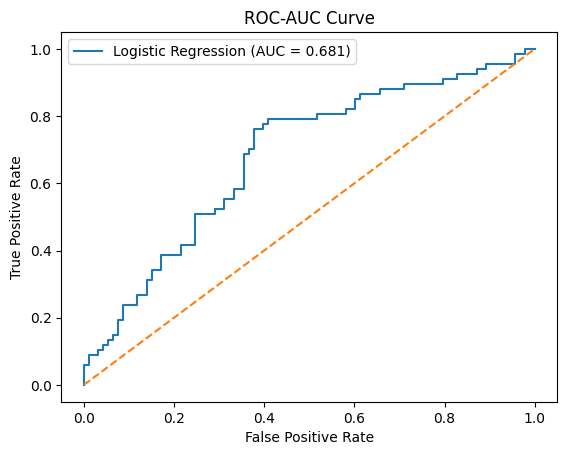

ROC-AUC Score: 0.6808


In [19]:
from sklearn.metrics import roc_curve, roc_auc_score

y_probability = model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(
    (y_test == 'Yes').astype(int),
    y_probability
)

fpr, tpr, thresholds = roc_curve(
    (y_test == 'Yes').astype(int),
    y_probability
)

plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve')
plt.legend()
plt.show()

print("ROC-AUC Score:", round(auc, 4))

In [20]:
from sklearn.ensemble import RandomForestClassifier

In [21]:
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced'
    ))
])

In [22]:
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [23]:
rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred, pos_label='Yes')
rf_recall = recall_score(y_test, rf_pred, pos_label='Yes')
rf_f1 = f1_score(y_test, rf_pred, pos_label='Yes')

print("Random Forest Evaluation")
print("------------------------")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-Score:", round(rf_f1, 4))

Random Forest Evaluation
------------------------
Accuracy: 0.5938
Precision: 0.5152
Recall: 0.5075
F1-Score: 0.5113


In [24]:
churn_probabilities = model.predict_proba(X)[:, 1]

predictions = pd.DataFrame({
    'CustomerID': df['CustomerID'],
    'Actual_Churn': y,
    'Predicted_Churn': model.predict(X),
    'Churn_Probability': churn_probabilities
})

print(predictions.head(10))

    CustomerID Actual_Churn Predicted_Churn  Churn_Probability
0  CUST-100001          Yes             Yes           0.707486
1  CUST-100002          Yes              No           0.241597
2  CUST-100003          Yes              No           0.251721
3  CUST-100004          Yes              No           0.444151
4  CUST-100005           No              No           0.406282
5  CUST-100006           No              No           0.209837
6  CUST-100007           No              No           0.229979
7  CUST-100008          Yes             Yes           0.682805
8  CUST-100009           No              No           0.248835
9  CUST-100010          Yes             Yes           0.658218


In [25]:
predictions.to_csv('churn_predictions.csv', index=False)

print("Predictions exported successfully!")

Predictions exported successfully!


In [26]:
from google.colab import files

files.download('churn_predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Logistic Regression': [accuracy, precision, recall, f1],
    'Random Forest': [rf_accuracy, rf_precision, rf_recall, rf_f1]
})

print(comparison)

      Metric  Logistic Regression  Random Forest
0   Accuracy             0.637500       0.593750
1  Precision             0.576271       0.515152
2     Recall             0.507463       0.507463
3   F1-Score             0.539683       0.511278


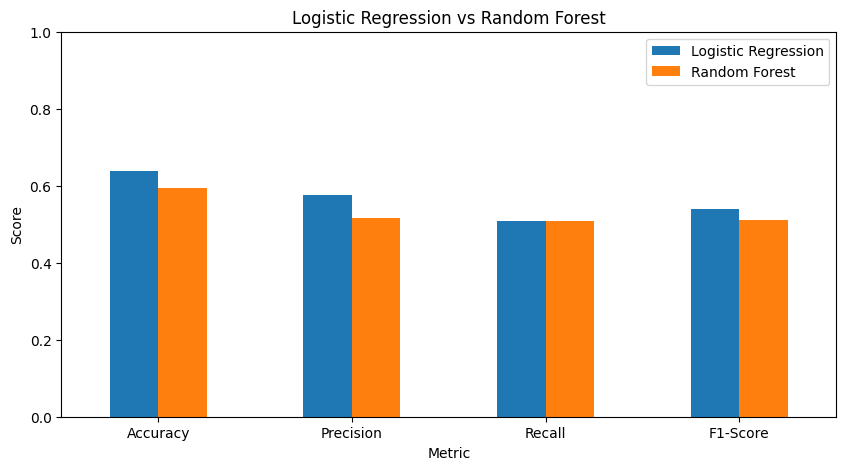

In [29]:
comparison.set_index('Metric').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Logistic Regression vs Random Forest')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()

                             Feature  Importance
3               num__TotalChargesINR    0.122876
1                  num__TenureMonths    0.121853
2             num__MonthlyChargesINR    0.119830
0                           num__Age    0.110418
5                  num__LatePayments    0.080698
4                num__SupportTickets    0.072810
14  cat__ContractType_Month-to-Month    0.071972
15        cat__ContractType_One Year    0.034520
16        cat__ContractType_Two Year    0.028960
9                  cat__Region_South    0.023446


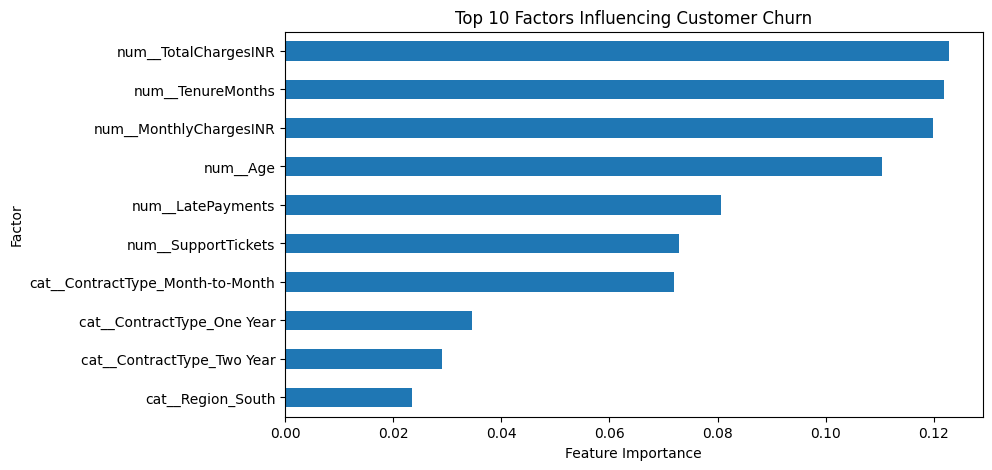

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

feature_names = rf_model.named_steps['preprocessor'].get_feature_names_out()
importance_values = rf_model.named_steps['classifier'].feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_values
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).head(10)

print(importance_df)

importance_df.sort_values('Importance').plot(
    x='Feature',
    y='Importance',
    kind='barh',
    figsize=(9, 5),
    legend=False
)

plt.title('Top 10 Factors Influencing Customer Churn')
plt.xlabel('Feature Importance')
plt.ylabel('Factor')
plt.show()

In [31]:
# Train the final model using the complete dataset
final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

final_model.fit(X, y)

# Find the probability of churn
yes_index = list(final_model.classes_).index('Yes')
churn_probability = final_model.predict_proba(X)[:, yes_index]

# Create prediction file
predictions = pd.DataFrame({
    'CustomerID': df['CustomerID'],
    'Actual_Churn': y,
    'Predicted_Churn': final_model.predict(X),
    'Churn_Probability': churn_probability
})

# Save as CSV
predictions.to_csv('churn_predictions.csv', index=False)

print(predictions.head())
print("Prediction file created successfully!")

    CustomerID Actual_Churn Predicted_Churn  Churn_Probability
0  CUST-100001          Yes             Yes           0.666417
1  CUST-100002          Yes              No           0.242561
2  CUST-100003          Yes              No           0.278108
3  CUST-100004          Yes              No           0.477318
4  CUST-100005           No              No           0.397900
Prediction file created successfully!


In [32]:
from google.colab import files
files.download('churn_predictions.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
total_customers = len(df)

churned_customers = (df['Churn'] == 'Yes').sum()

churn_rate = (churned_customers / total_customers) * 100

monthly_revenue_loss = df.loc[
    df['Churn'] == 'Yes',
    'MonthlyChargesINR'
].sum()

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Churn Rate:", round(churn_rate, 2), "%")
print("Estimated Monthly Revenue Loss: ₹", round(monthly_revenue_loss, 2))

Total Customers: 800
Churned Customers: 334
Churn Rate: 41.75 %
Estimated Monthly Revenue Loss: ₹ 250382.29


In [34]:
df['CustomerLifetimeValue'] = (
    df['MonthlyChargesINR'] * df['TenureMonths']
)

print("Average Customer Lifetime Value: ₹",
      round(df['CustomerLifetimeValue'].mean(), 2))

print("Average CLV of Churned Customers: ₹",
      round(
          df.loc[df['Churn'] == 'Yes', 'CustomerLifetimeValue'].mean(),
          2
      ))

print("Average CLV of Retained Customers: ₹",
      round(
          df.loc[df['Churn'] == 'No', 'CustomerLifetimeValue'].mean(),
          2
      ))

Average Customer Lifetime Value: ₹ 28017.59
Average CLV of Churned Customers: ₹ 27183.31
Average CLV of Retained Customers: ₹ 28615.55


In [35]:
contract_churn = pd.crosstab(
    df['ContractType'],
    df['Churn'],
    normalize='index'
) * 100

print(contract_churn.round(2))

Churn              No    Yes
ContractType                
Month-to-Month  40.97  59.03
One Year        77.21  22.79
Two Year        80.39  19.61


In [36]:
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

print(payment_churn.round(2))

Churn             No    Yes
PaymentMethod              
Card           61.11  38.89
Net Banking    58.79  41.21
UPI            55.92  44.08
Wallet         57.29  42.71


In [37]:
subscription_churn = pd.crosstab(
    df['SubscriptionType'],
    df['Churn'],
    normalize='index'
) * 100

print(subscription_churn.round(2))

Churn                No    Yes
SubscriptionType              
Basic             58.99  41.01
Pro               58.04  41.96
Standard          57.68  42.32


In [38]:
print("CUSTOMER CHURN ANALYSIS SUMMARY")
print("--------------------------------")
print("Total Customers:", len(df))
print("Churned Customers:", (df['Churn'] == 'Yes').sum())
print("Churn Rate:", round(churn_rate, 2), "%")
print("Monthly Revenue Loss: ₹", round(monthly_revenue_loss, 2))

print("\nCUSTOMER LIFETIME VALUE")
print("Overall CLV: ₹", round(df['CustomerLifetimeValue'].mean(), 2))
print("Churned CLV: ₹", round(df.loc[df['Churn'] == 'Yes', 'CustomerLifetimeValue'].mean(), 2))
print("Retained CLV: ₹", round(df.loc[df['Churn'] == 'No', 'CustomerLifetimeValue'].mean(), 2))

print("\nMODEL PERFORMANCE")
print("Logistic Regression Accuracy:", round(accuracy, 4))
print("Logistic Regression F1:", round(f1, 4))
print("Random Forest Accuracy:", round(rf_accuracy, 4))
print("Random Forest F1:", round(rf_f1, 4))

CUSTOMER CHURN ANALYSIS SUMMARY
--------------------------------
Total Customers: 800
Churned Customers: 334
Churn Rate: 41.75 %
Monthly Revenue Loss: ₹ 250382.29

CUSTOMER LIFETIME VALUE
Overall CLV: ₹ 28017.59
Churned CLV: ₹ 27183.31
Retained CLV: ₹ 28615.55

MODEL PERFORMANCE
Logistic Regression Accuracy: 0.6375
Logistic Regression F1: 0.5397
Random Forest Accuracy: 0.5938
Random Forest F1: 0.5113


In [39]:
report = f"""
# Customer Churn Prediction and Analysis

## 1. Project Overview

This project analyses customer subscription data to identify churn patterns,
estimate customer lifetime value, and build machine-learning models to predict
customer churn.

## 2. Dataset Overview

- Total customers: {len(df)}
- Total features: 11 (excluding CustomerID and Churn)
- Churned customers: {(df['Churn'] == 'Yes').sum()}
- Retained customers: {(df['Churn'] == 'No').sum()}

## 3. Business Metrics

- Churn Rate: {churn_rate:.2f}%
- Estimated Monthly Revenue Loss: Rs. {monthly_revenue_loss:,.2f}
- Average Customer Lifetime Value: Rs. {df['CustomerLifetimeValue'].mean():,.2f}
- Average CLV of Churned Customers: Rs. {df.loc[df['Churn'] == 'Yes', 'CustomerLifetimeValue'].mean():,.2f}
- Average CLV of Retained Customers: Rs. {df.loc[df['Churn'] == 'No', 'CustomerLifetimeValue'].mean():,.2f}

## 4. Machine Learning Models

Two classification algorithms were trained:

1. Logistic Regression
2. Random Forest Classifier

An 80:20 train-test split was used.

### Model Performance

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | {accuracy:.4f} | {rf_accuracy:.4f} |
| Precision | {precision:.4f} | {rf_precision:.4f} |
| Recall | {recall:.4f} | {rf_recall:.4f} |
| F1-Score | {f1:.4f} | {rf_f1:.4f} |

Logistic Regression achieved better accuracy and F1-score on the test set.
It was selected for generating the final customer predictions.

## 5. Churn Analysis by Contract Type

{contract_churn.round(2).to_string()}

Month-to-month customers showed the highest churn rate.

## 6. Churn Analysis by Payment Method

{payment_churn.round(2).to_string()}

UPI users showed the highest churn rate among the payment methods.

## 7. Churn Analysis by Subscription Type

{subscription_churn.round(2).to_string()}

Standard subscription customers showed the highest churn rate, although
the differences between subscription types were small.

## 8. Feature Importance

The Random Forest model was used to rank the features by predictive importance.

{importance_df.to_string(index=False)}

Feature importance indicates how much the model relied on each feature.
It does not establish causation.

## 9. Business Recommendations

1. Encourage month-to-month customers to consider annual contracts.
2. Investigate payment difficulties among UPI and Wallet users.
3. Monitor customers with behavioural patterns associated with higher churn.
4. Introduce customer retention campaigns and loyalty benefits.
5. Improve customer support and investigate recurring service issues.

## 10. Conclusion

The dataset showed an overall churn rate of {churn_rate:.2f}%.
Logistic Regression performed better than Random Forest on the reported
test-set accuracy and F1-score.

The analysis identifies contract type and payment method as useful
areas for further customer-retention investigation.

The predictions and metrics should be interpreted in the context of
the dataset and the limitations of the trained models.
"""

with open("report.md", "w", encoding="utf-8") as file:
    file.write(report)

print("Final report created successfully!")

Final report created successfully!


In [40]:
from google.colab import files
files.download('report.md')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
!pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 14.3 MB/s  0:00:00


In [42]:
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from xml.sax.saxutils import escape

styles = getSampleStyleSheet()

title_style = ParagraphStyle(
    'ReportTitle',
    parent=styles['Title'],
    alignment=TA_CENTER,
    fontSize=20,
    spaceAfter=20
)

heading_style = styles['Heading2']
body_style = styles['BodyText']

story = []
table_lines = []

def add_table():
    if not table_lines:
        return

    rows = []
    for line in table_lines:
        cells = [cell.strip() for cell in line.strip('|').split('|')]
        if all(set(cell) <= {'-', ':'} for cell in cells):
            continue
        rows.append([Paragraph(escape(cell), body_style) for cell in cells])

    if rows:
        table = Table(rows, repeatRows=1)
        table.setStyle(TableStyle([
            ('BACKGROUND', (0, 0), (-1, 0), colors.lightblue),
            ('TEXTCOLOR', (0, 0), (-1, 0), colors.black),
            ('GRID', (0, 0), (-1, -1), 0.5, colors.grey),
            ('VALIGN', (0, 0), (-1, -1), 'TOP'),
            ('PADDING', (0, 0), (-1, -1), 7)
        ]))
        story.append(table)
        story.append(Spacer(1, 12))

    table_lines.clear()

with open('report.md', 'r', encoding='utf-8') as file:
    lines = file.readlines()

for line in lines:
    line = line.strip()

    if line.startswith('|'):
        table_lines.append(line)
        continue

    add_table()

    if not line:
        story.append(Spacer(1, 6))
    elif line.startswith('# '):
        story.append(Paragraph(escape(line[2:]), title_style))
    elif line.startswith('## '):
        story.append(Paragraph(escape(line[3:]), heading_style))
    elif line.startswith('- '):
        story.append(Paragraph('• ' + escape(line[2:]), body_style))
    elif line[:1].isdigit() and '. ' in line:
        story.append(Paragraph(escape(line), body_style))
    else:
        story.append(Paragraph(escape(line), body_style))

add_table()

pdf = SimpleDocTemplate(
    'Customer_Churn_Analysis_Report.pdf',
    pagesize=(8.27 * inch, 11.69 * inch),
    rightMargin=50,
    leftMargin=50,
    topMargin=50,
    bottomMargin=50
)

pdf.build(story)

print("PDF report created successfully!")

PDF report created successfully!


In [43]:
from google.colab import files
files.download('Customer_Churn_Analysis_Report.pdf')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>